In [1]:
import numpy as np
import time
import torch
import matplotlib.pyplot as plt
plt.rc('text', usetex=False)
import multiprocessing as mp
from typing import Union


from abc import ABC
from epde.preprocessing.cheb import process_point_cheb

from epde.preprocessing.deriv_calculators import Heatmap, AbstractDeriv, AdaptiveFiniteDeriv, PolynomialDeriv, SpectralDeriv, TotalVariation




Mean Squared Error (MSE) for noise level 0:
  u_xx: 0.789784907558386
  u_x: 0.006119746128734238
  u_t: 0.0008819817814561395
Mean Squared Error (MSE) for noise level 0.005:
  u_xx: 0.7936084654300173
  u_x: 0.0061331204495727425
  u_t: 0.0009082733219162992
Mean Squared Error (MSE) for noise level 0.01:
  u_xx: 2.341602058614526
  u_x: 0.014563760244433892
  u_t: 0.13739356162262711


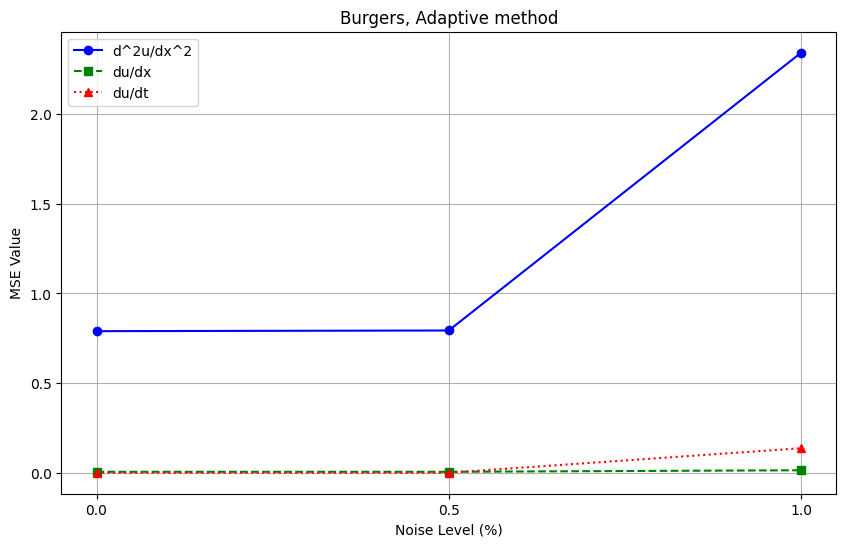

In [6]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xx = []
mse_values_u_x = []
mse_values_u_t = []

for noise in noise_levels:
    u_xx = np.load(f'Burgers_Gradient_xx_noise{noise}.npy')
    u_x = np.load(f'Burgers_Gradient_x_noise{noise}.npy')
    u_t = np.load(f'Burgers_Gradient_t_noise{noise}.npy')
    

    gradient_xx = np.load(f'Burgers_Adaptive_xx_noise{noise}.npy')
    gradient_x = np.load(f'Burgers_Adaptive_x_noise{noise}.npy')
    gradient_t = np.load(f'Burgers_Adaptive_t_noise{noise}.npy')
    
    u_xx = u_xx[5:27, 5:27]
    u_x = u_x[5:27, 5:27]
    u_t = u_t[5:27, 5:27]
    
    gradient_xx = gradient_xx[5:27, 5:27]
    gradient_x = gradient_x[5:27, 5:27]
    gradient_t = gradient_t[5:27, 5:27]

    # Вычисление MSE для каждого случая
    mse_u_xx = calculate_mse(u_xx, gradient_xx)
    mse_u_x = calculate_mse(u_x, gradient_x)
    mse_u_t = calculate_mse(u_t, gradient_t)
    
    mse_values_u_xx.append(mse_u_xx)
    mse_values_u_x.append(mse_u_x)
    mse_values_u_t.append(mse_u_t)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xx: {mse_u_xx}')
    print(f'  u_x: {mse_u_x}')
    print(f'  u_t: {mse_u_t}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xx, marker='o', linestyle='-', color='b', label='d^2u/dx^2')
plt.plot(noise_levels_percent, mse_values_u_x, marker='s', linestyle='--', color='g', label='du/dx')
plt.plot(noise_levels_percent, mse_values_u_t, marker='^', linestyle=':', color='r', label='du/dt')

plt.title('Burgers, Adaptive method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Burgers_Adaptive_error.pdf', format='pdf')
plt.show()


In [9]:
u_xx

array([[ -4.14301415,  -6.50227816,  -7.97262005,  -8.84181595,
         -9.85936701, -11.62890452, -12.54568584, -10.76951902,
         -9.17389666,  -7.4503317 ,  -3.74904328,   1.55960433,
          6.3266332 ,   9.18728927,  12.05267889,  14.56899583,
         13.55787079,   9.4828634 ,   7.92851378,   8.19340443,
          7.11829557,   5.28522775],
       [ -4.30751857,  -6.38557017,  -6.7752445 ,  -7.89646052,
         -9.80118827, -10.43361041, -12.53247602, -13.17525124,
        -10.98912727,  -8.25729912,  -4.03818917,   1.8335581 ,
          7.29535126,  10.6144672 ,  13.20419741,  14.50003741,
         12.89470615,  11.04987453,   8.60248325,   6.38702691,
          6.18804113,   4.26788388],
       [ -3.42731717,  -5.56117878,  -6.30899363,  -6.84510609,
         -9.23124047, -11.68268575, -12.98138155, -13.2612156 ,
        -12.8469823 ,  -9.59342466,  -4.05677002,   2.02637379,
          7.52376458,  11.74723707,  15.02157958,  15.89639627,
         13.03941533,  10.1320

Mean Squared Error (MSE) for noise level 0:
  u_xx: 1.3151484965238818
  u_x: 0.08202448173412169
  u_t: 0.0010008050813983139
Mean Squared Error (MSE) for noise level 0.005:
  u_xx: 1.3863941661222563
  u_x: 0.08324954721914796
  u_t: 0.02060010088732487
Mean Squared Error (MSE) for noise level 0.01:
  u_xx: 2.550201994971136
  u_x: 0.08680109422068369
  u_t: 0.04736944886657428


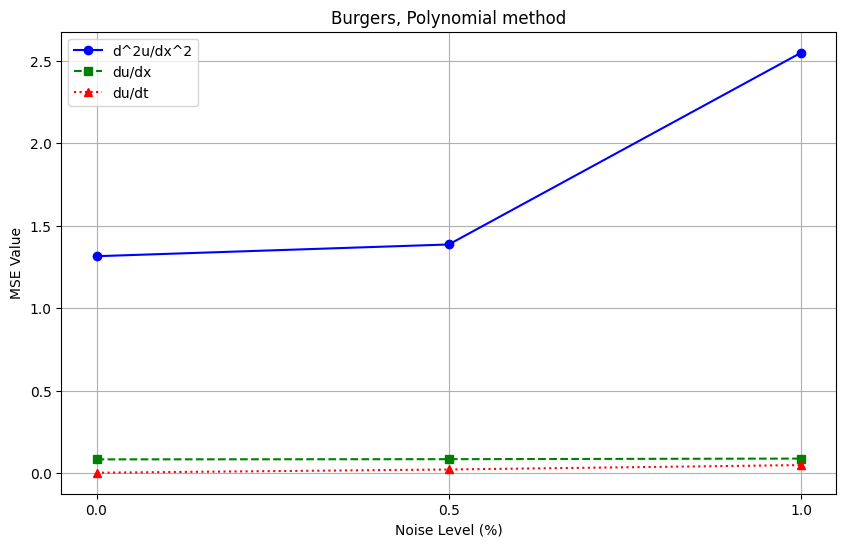

In [11]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xx = []
mse_values_u_x = []
mse_values_u_t = []

for noise in noise_levels:
    u_xx = np.load(f'Burgers_Gradient_xx_noise{noise}.npy')
    u_x = np.load(f'Burgers_Gradient_x_noise{noise}.npy')
    u_t = np.load(f'Burgers_Gradient_t_noise{noise}.npy')
    
    gradient_xx = np.load(f'Burgers_Polynomial_xx_noise{noise}.npy')
    gradient_x = np.load(f'Burgers_Polynomial_x_noise{noise}.npy')
    gradient_t = np.load(f'Burgers_Polynomial_t_noise{noise}.npy')

    u_xx = u_xx[5:27, 5:27]
    u_x = u_x[5:27, 5:27]
    u_t = u_t[5:27, 5:27]
    
    gradient_xx = gradient_xx[5:27, 5:27]
    gradient_x = gradient_x[5:27, 5:27]
    gradient_t = gradient_t[5:27, 5:27]

    
    
    # Вычисление MSE для каждого случая
    mse_u_xx = calculate_mse(u_xx, gradient_xx)
    mse_u_x = calculate_mse(u_x, gradient_x)
    mse_u_t = calculate_mse(u_t, gradient_t)
    
    mse_values_u_xx.append(mse_u_xx)
    mse_values_u_x.append(mse_u_x)
    mse_values_u_t.append(mse_u_t)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xx: {mse_u_xx}')
    print(f'  u_x: {mse_u_x}')
    print(f'  u_t: {mse_u_t}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xx, marker='o', linestyle='-', color='b', label='d^2u/dx^2')
plt.plot(noise_levels_percent, mse_values_u_x, marker='s', linestyle='--', color='g', label='du/dx')
plt.plot(noise_levels_percent, mse_values_u_t, marker='^', linestyle=':', color='r', label='du/dt')

plt.title('Burgers, Polynomial method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Burgers_Polynomial_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_xx: 6.385479624446129
  u_x: 0.01556778650643253
  u_t: 0.21126452421407563
Mean Squared Error (MSE) for noise level 0.005:
  u_xx: 6.489683727168177
  u_x: 0.016178669076981254
  u_t: 0.22753860226446387
Mean Squared Error (MSE) for noise level 0.01:
  u_xx: 7.215170475810703
  u_x: 0.019953860630121452
  u_t: 0.2652018748243342


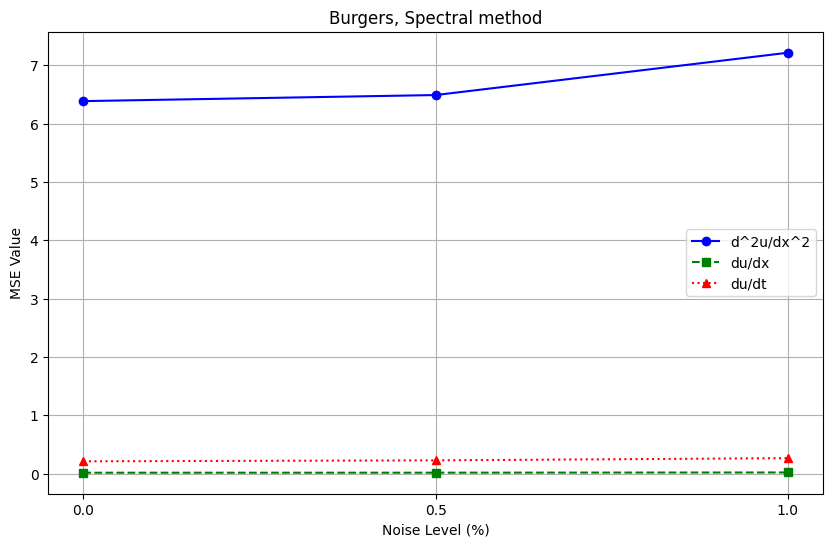

In [15]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xx = []
mse_values_u_x = []
mse_values_u_t = []

for noise in noise_levels:
    u_xx = np.load(f'Burgers_Gradient_xx_noise{noise}.npy')
    u_x = np.load(f'Burgers_Gradient_x_noise{noise}.npy')
    u_t = np.load(f'Burgers_Gradient_t_noise{noise}.npy')
    
    gradient_xx = np.load(f'Burgers_Spectral_xx_noise{noise}.npy')
    gradient_x = np.load(f'Burgers_Spectral_x_noise{noise}.npy')
    gradient_t = np.load(f'Burgers_Spectral_t_noise{noise}.npy')
    
    u_xx = u_xx[5:27, 5:27]
    u_x = u_x[5:27, 5:27]
    u_t = u_t[5:27, 5:27]
    
    gradient_xx = gradient_xx[5:27, 5:27]
    gradient_x = gradient_x[5:27, 5:27]
    gradient_t = gradient_t[5:27, 5:27]

    # Вычисление MSE для каждого случая
    mse_u_xx = calculate_mse(u_xx, gradient_xx)
    mse_u_x = calculate_mse(u_x, gradient_x)
    mse_u_t = calculate_mse(u_t, gradient_t)
    
    mse_values_u_xx.append(mse_u_xx)
    mse_values_u_x.append(mse_u_x)
    mse_values_u_t.append(mse_u_t)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xx: {mse_u_xx}')
    print(f'  u_x: {mse_u_x}')
    print(f'  u_t: {mse_u_t}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xx, marker='o', linestyle='-', color='b', label='d^2u/dx^2')
plt.plot(noise_levels_percent, mse_values_u_x, marker='s', linestyle='--', color='g', label='du/dx')
plt.plot(noise_levels_percent, mse_values_u_t, marker='^', linestyle=':', color='r', label='du/dt')

plt.title('Burgers, Spectral method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Burgers_Spectral_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_xx: 206.60640674104863
  u_x: 5.478284781449928
  u_t: 0.8751080565358168
Mean Squared Error (MSE) for noise level 0.005:
  u_xx: 207.61532283093598
  u_x: 5.490398487108481
  u_t: 0.9017981352086732
Mean Squared Error (MSE) for noise level 0.01:
  u_xx: 207.616332414539
  u_x: 5.491716697765896
  u_t: 0.9020182877669737


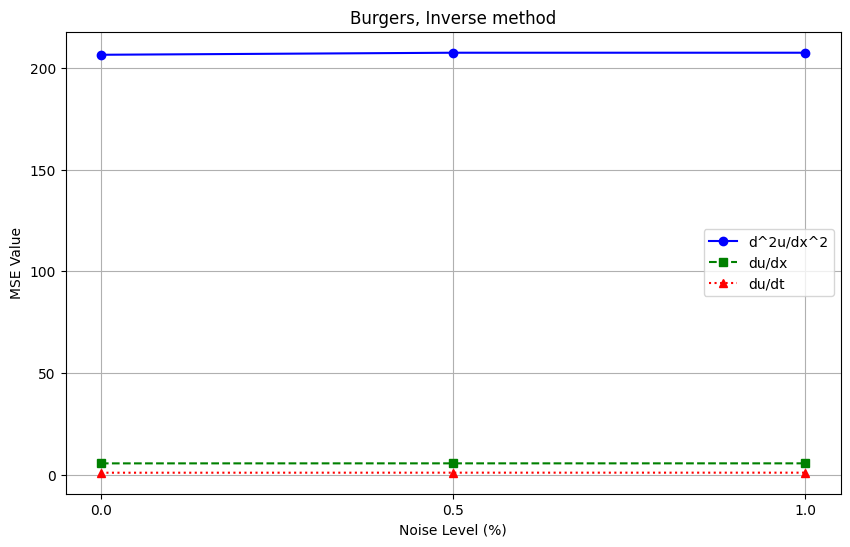

In [6]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xx = []
mse_values_u_x = []
mse_values_u_t = []

for noise in noise_levels:
    u_xx = np.load(f'Burgers_Gradient_xx_noise{noise}.npy')
    u_x = np.load(f'Burgers_Gradient_x_noise{noise}.npy')
    u_t = np.load(f'Burgers_Gradient_t_noise{noise}.npy')
    
    gradient_xx = np.load(f'Burgers_Inverse_xx_noise{noise}.npy')
    gradient_x = np.load(f'Burgers_Inverse_x_noise{noise}.npy')
    gradient_t = np.load(f'Burgers_Inverse_t_noise{noise}.npy')

    u_xx = u_xx[5:27, 5:27]
    u_x = u_x[5:27, 5:27]
    u_t = u_t[5:27, 5:27]
    
    gradient_xx = gradient_xx[5:27, 5:27]
    gradient_x = gradient_x[5:27, 5:27]
    gradient_t = gradient_t[5:27, 5:27]  
     
    # Вычисление MSE для каждого случая
    mse_u_xx = calculate_mse(u_xx, gradient_xx)
    mse_u_x = calculate_mse(u_x, gradient_x)
    mse_u_t = calculate_mse(u_t, gradient_t)
    
    mse_values_u_xx.append(mse_u_xx)
    mse_values_u_x.append(mse_u_x)
    mse_values_u_t.append(mse_u_t)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xx: {mse_u_xx}')
    print(f'  u_x: {mse_u_x}')
    print(f'  u_t: {mse_u_t}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xx, marker='o', linestyle='-', color='b', label='d^2u/dx^2')
plt.plot(noise_levels_percent, mse_values_u_x, marker='s', linestyle='--', color='g', label='du/dx')
plt.plot(noise_levels_percent, mse_values_u_t, marker='^', linestyle=':', color='r', label='du/dt')

plt.title('Burgers, Inverse method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Burgers_Inverse_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_xx: 208.96179116843774
  u_x: 6.242834610404744
  u_t: 0.7988134846039396
Mean Squared Error (MSE) for noise level 0.005:
  u_xx: 209.9771648378559
  u_x: 6.256836283926487
  u_t: 0.8239567492612216
Mean Squared Error (MSE) for noise level 0.01:
  u_xx: 209.97047214462296
  u_x: 6.25600542491876
  u_t: 0.8236346277656266


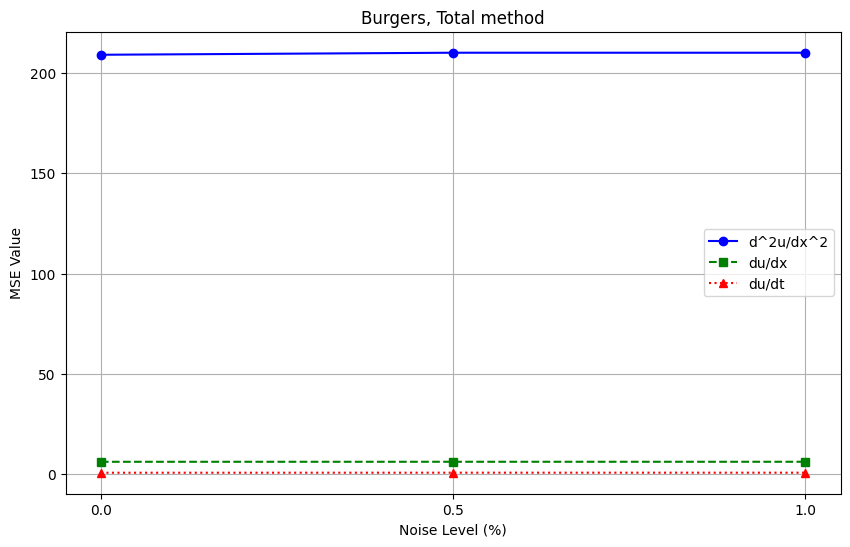

In [8]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xx = []
mse_values_u_x = []
mse_values_u_t = []

for noise in noise_levels:
    u_xx = np.load(f'Burgers_Gradient_xx_noise{noise}.npy')
    u_x = np.load(f'Burgers_Gradient_x_noise{noise}.npy')
    u_t = np.load(f'Burgers_Gradient_t_noise{noise}.npy')
    
    gradient_xx = np.load(f'Burgers_Total_xx_noise{noise}.npy')
    gradient_x = np.load(f'Burgers_Total_x_noise{noise}.npy')
    gradient_t = np.load(f'Burgers_Total_t_noise{noise}.npy')

    u_xx = u_xx[5:27, 5:27]
    u_x = u_x[5:27, 5:27]
    u_t = u_t[5:27, 5:27]
    
    gradient_xx = gradient_xx[5:27, 5:27]
    gradient_x = gradient_x[5:27, 5:27]
    gradient_t = gradient_t[5:27, 5:27]  
        
    # Вычисление MSE для каждого случая
    mse_u_xx = calculate_mse(u_xx, gradient_xx)
    mse_u_x = calculate_mse(u_x, gradient_x)
    mse_u_t = calculate_mse(u_t, gradient_t)
    
    mse_values_u_xx.append(mse_u_xx)
    mse_values_u_x.append(mse_u_x)
    mse_values_u_t.append(mse_u_t)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xx: {mse_u_xx}')
    print(f'  u_x: {mse_u_x}')
    print(f'  u_t: {mse_u_t}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xx, marker='o', linestyle='-', color='b', label='d^2u/dx^2')
plt.plot(noise_levels_percent, mse_values_u_x, marker='s', linestyle='--', color='g', label='du/dx')
plt.plot(noise_levels_percent, mse_values_u_t, marker='^', linestyle=':', color='r', label='du/dt')

plt.title('Burgers, Total method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Burgers_Total_error.pdf', format='pdf')
plt.show()
